In [78]:
import cv2
import mediapipe as mp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import numpy as np

In [79]:
# Configure MediaPipe
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=VisionRunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=True
)

# Open video
video_path = "data/test_video.mov"
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"FPS: {fps}, Frames: {total_frames}")


FPS: 29.998430778235036, Frames: 35366


In [80]:
results_list = []
n = 1000
step = 10

error_n = 0
# Process video
with FaceLandmarker.create_from_options(options) as landmarker:
    frame_idx = 0
    while cap.isOpened() and frame_idx < n*step:
        ret, frame = cap.read()
    
        if not ret:
            break

        timestamp_ms = int(frame_idx / fps * 1000)

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=frame_rgb
        )

        result = landmarker.detect_for_video(
            mp_image,
            timestamp_ms
        )

        if result.face_landmarks:
            h, w, _ = frame.shape

            for landmark in result.face_landmarks[0]:
                x = int(landmark.x * w)
                y = int(landmark.y * h)

                cv2.circle(
                    frame,
                    (x, y),
                    radius=1,
                    color=(0, 255, 0),
                    thickness=-1
                )

        if result.face_blendshapes:
            blendshapes = result.face_blendshapes[0]
        
            blendshape_features = {
                category.category_name: category.score
                for category in blendshapes
            }
            blendshape_features['frame_idx'] = frame_idx
            results_list.append(blendshape_features)
        else:
            print("No face found")
            error_n += 1

        if False:
            plt.clf()
            plt.figure(figsize=(10, 6))
            plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            plt.title(f"Frame: {frame_idx}")
            plt.axis("off")
            display(plt.gcf())
            clear_output(wait=True)
            
        print(frame_idx)
        frame_idx += step

cap.release()

df = pd.DataFrame(results_list)

print(f'Found object in {len(df)} of {n} samples')

No face found
0
No face found
10
No face found
20
No face found
30
No face found
40
No face found
50
No face found
60
No face found
70
No face found
80
No face found
90
No face found
100
No face found
110
No face found
120
No face found
130
No face found
140
No face found
150
No face found
160
170
180
190
200
210
220
230
240
250
260
270
280
290
300
310
320
330
340
350
360
370
380
390
400
410
420
430
440
450
460
470
480
490
500
510
520
530
540
550
560
570
580
590
600
610
620
630
640
650
660
670
680
690
700
710
720
730
740
750
760
770
780
790
800
810
820
830
840
850
860
870
880
890
900
910
920
930
940
950
960
970
980
990
1000
1010
1020
1030
1040
1050
1060
1070
1080
1090
1100
1110
1120
1130
1140
1150
1160
1170
1180
1190
1200
1210
1220
1230
1240
1250
1260
1270
1280
1290
1300
1310
1320
1330
1340
1350
1360
1370
1380
1390
1400
1410
1420
1430
1440
1450
1460
1470
1480
1490
1500
1510
1520
1530
1540
1550
1560
1570
1580
1590
1600
1610
1620
1630
1640
1650
1660
1670
1680
1690
1700
1710
1720
1730
174

In [81]:
display(df)

,_neutral,browDownLeft,browDownRight,browInnerUp,browOuterUpLeft,browOuterUpRight,cheekPuff,cheekSquintLeft,cheekSquintRight,eyeBlinkLeft,...,mouthShrugUpper,mouthSmileLeft,mouthSmileRight,mouthStretchLeft,mouthStretchRight,mouthUpperUpLeft,mouthUpperUpRight,noseSneerLeft,noseSneerRight,frame_idx
0,1.124604e-06,0.000156,0.000080,0.717735,0.584941,0.649571,0.000055,3.871457e-07,7.488090e-07,0.098459,...,0.000730,0.002423,0.002477,0.002837,0.001524,0.000004,0.000009,3.731155e-07,4.131274e-07,170
1,8.479083e-07,0.000223,0.000090,0.708822,0.577323,0.647910,0.000055,2.572845e-07,3.537442e-07,0.125367,...,0.000530,0.013559,0.021359,0.002390,0.003210,0.000008,0.000017,3.447515e-07,3.153957e-07,180
2,8.288133e-07,0.000260,0.000132,0.683375,0.530280,0.543690,0.000045,3.191314e-07,2.557575e-07,0.130922,...,0.000887,0.014859,0.028187,0.002615,0.003518,0.000014,0.000028,3.838952e-07,2.733782e-07,190
3,8.548079e-07,0.000276,0.000145,0.657895,0.539142,0.577158,0.000046,2.727084e-07,3.064307e-07,0.125399,...,0.000692,0.009372,0.013674,0.001986,0.002073,0.000008,0.000014,3.501421e-07,2.800587e-07,200
4,9.306243e-07,0.000239,0.000136,0.690763,0.560652,0.581691,0.000046,2.885244e-07,3.027732e-07,0.114956,...,0.000595,0.006378,0.009646,0.001310,0.001680,0.000006,0.000010,2.811996e-07,2.731350e-07,210
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978,3.667554e-07,0.000092,0.000249,0.749413,0.750628,0.329622,0.000013,1.591291e-07,6.389414e-08,0.035504,...,0.001494,0.000305,0.003361,0.000041,0.005336,0.000002,0.000008,2.820531e-07,7.811663e-08,9950
979,3.850065e-07,0.000083,0.000246,0.749292,0.762813,0.331927,0.000014,1.689632e-07,6.724166e-08,0.036347,...,0.001589,0.000310,0.003368,0.000038,0.005095,0.000002,0.000009,2.812203e-07,7.940842e-08,9960
980,3.452519e-07,0.000092,0.000245,0.754295,0.734036,0.325761,0.000012,1.474902e-07,6.114197e-08,0.034984,...,0.001717,0.000211,0.002250,0.000033,0.003785,0.000002,0.000010,2.985007e-07,6.772989e-08,9970
981,3.261602e-07,0.000105,0.000233,0.756222,0.703028,0.336551,0.000010,1.249715e-07,6.515968e-08,0.034964,...,0.001458,0.000182,0.001688,0.000026,0.002712,0.000002,0.000008,2.981917e-07,5.918130e-08,9980


In [82]:
df.to_csv("video_features.csv", index=False)

In [83]:
if frame_idx % 5 != 0:
    frame_idx += 1

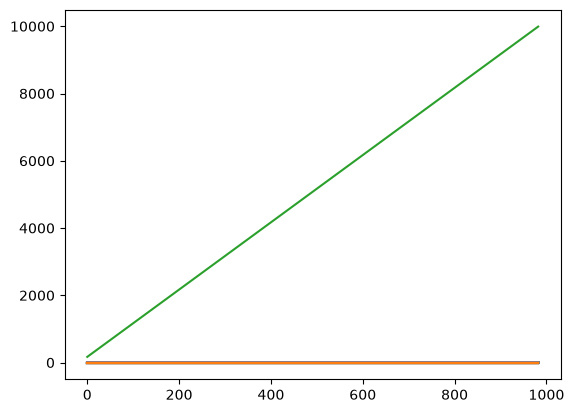

In [84]:
plt.plot(df)
plt.show()

In [85]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

pca = PCA(n_components=10)
X_pca = pca.fit_transform(df)

n_clusters = 10
kmeans = KMeans(random_state=42, n_init=10)
labels = kmeans.fit_predict(X_pca)

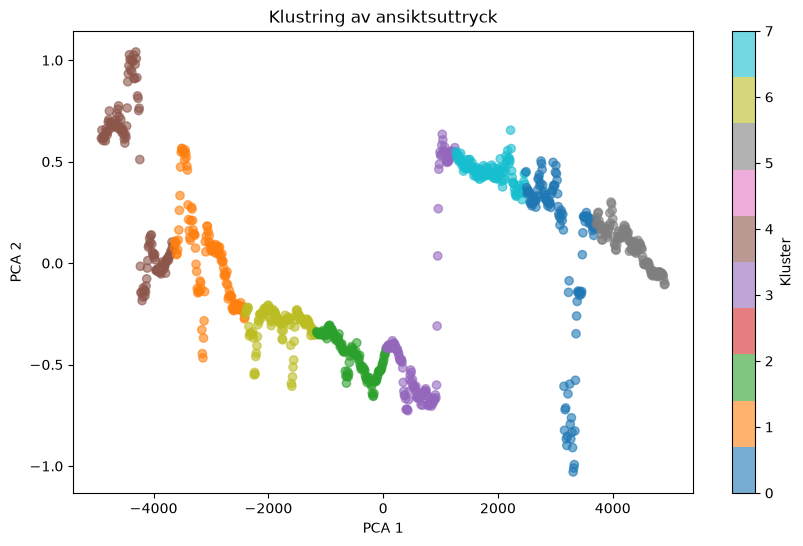

In [86]:
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', alpha=0.6)
plt.title("Klustring av ansiktsuttryck")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label='Kluster')
plt.show()

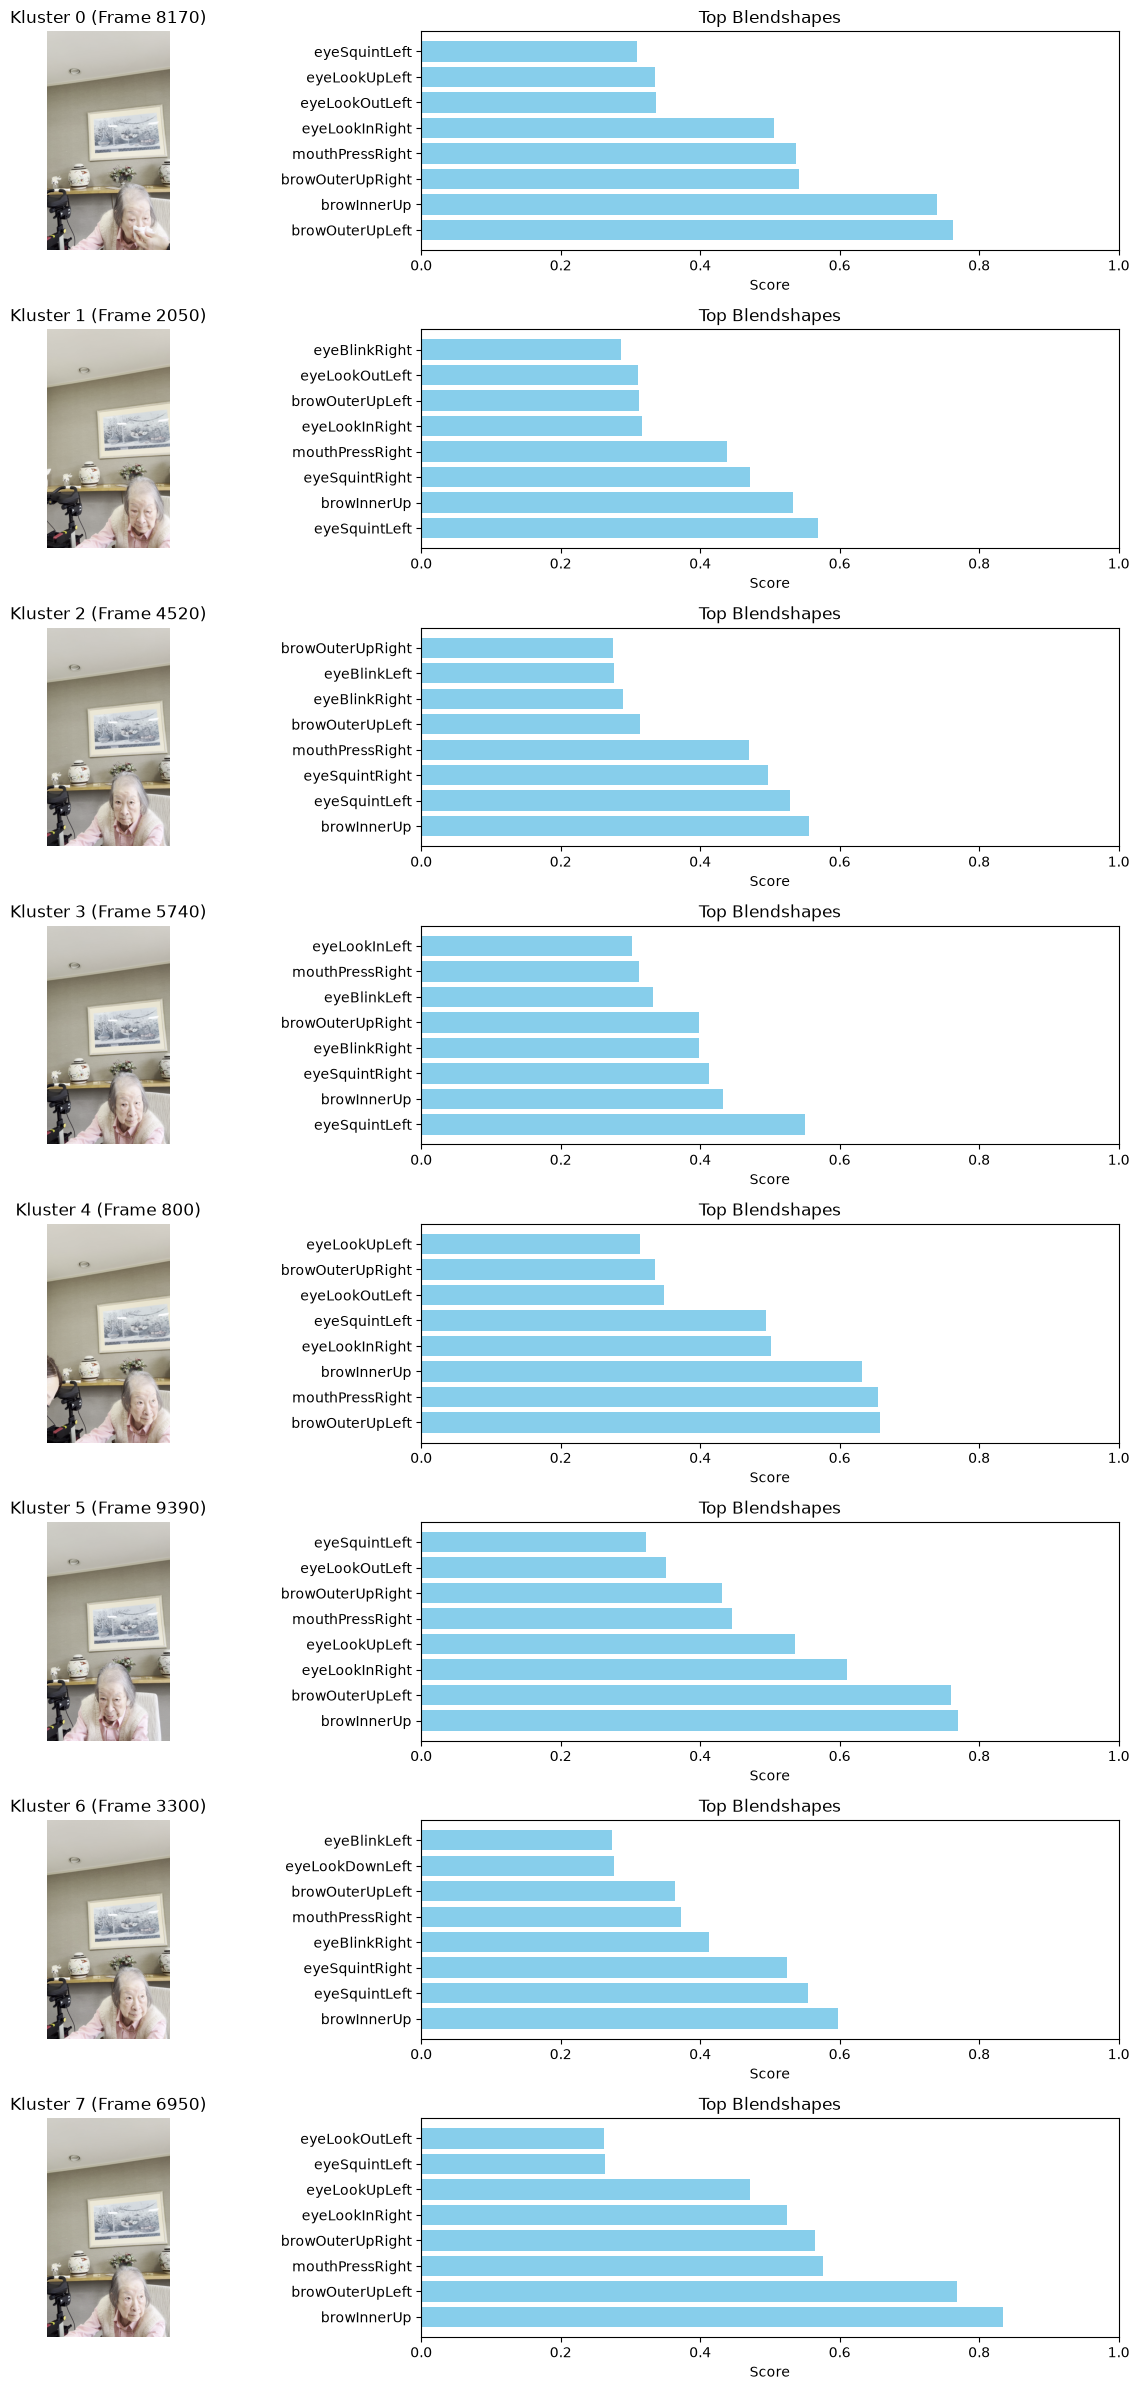

In [88]:
# Antal kluster du har (samma som n_clusters i din KMeans)
n_clusters = len(np.unique(labels))

# Hitta ursprungliga kolumnnamn för blendshapes (alla kolumner förutom 'frame_idx')
blendshape_cols = [col for col in df.columns if col != 'frame_idx']

plt.figure(figsize=(14, 3 * n_clusters))

for cluster_id in range(n_clusters):
    # Hitta alla index i vår DataFrame som tillhör detta kluster
    cluster_mask = (labels == cluster_id)
    cluster_indices = np.where(cluster_mask)[0]
    
    if len(cluster_indices) == 0:
        continue
        
    # Hitta punkten som ligger närmast klustrets centroid i PCA-rymden
    cluster_pca = X_pca[cluster_mask]
    cluster_centroid = np.mean(cluster_pca, axis=0)
    distances = np.linalg.norm(cluster_pca - cluster_centroid, axis=1)
    best_idx_in_cluster = cluster_indices[np.argmin(distances)]
    
    # Hämta motsvarande bildrutans index och läs in bilden från videon
    target_frame_idx = int(df.iloc[best_idx_in_cluster]['frame_idx'])
    
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, target_frame_idx)
    ret, frame = cap.read()
    cap.release()
    
    if not ret:
        continue
        
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Hämta de högsta blendshapes för detta kluster (medelvärde eller den bästa bilden)
    bs_values = df.iloc[best_idx_in_cluster][blendshape_cols].astype(float)
    top_features = bs_values.nlargest(8)  # Visa de 8 starkaste muskelrörelserna

    # --- Rita subplots: Bild till vänster, Stapeldiagram till höger ---
    
    # 1. Bilden
    plt.subplot(n_clusters, 2, cluster_id * 2 + 1)
    plt.imshow(frame_rgb)
    plt.title(f"Kluster {cluster_id} (Frame {target_frame_idx})")
    plt.axis('off')
    
    # 2. Stapeldiagrammet (Bars)
    plt.subplot(n_clusters, 2, cluster_id * 2 + 2)
    y_pos = np.arange(len(top_features))
    plt.barh(y_pos, top_features.values, align='center', color='skyblue')
    plt.yticks(y_pos, top_features.index)
    plt.xlabel("Score")
    plt.title("Top Blendshapes")
    plt.xlim(0, 1.0)

plt.tight_layout()
plt.show()